Import Required Libraries

In [1]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

# Train Test Split
from sklearn.model_selection import train_test_split

# Models
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

# Evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

Load Dataset

In [2]:
df = pd.read_csv("./heart/heart.csv")



In [3]:
# Display first 5 rows
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


Dataset Information

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [5]:
df.shape

(1025, 14)

In [6]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='str')

Check Missing Values

In [7]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Check Duplicate Records

In [8]:
df.duplicated().sum()

np.int64(723)

In [9]:
#remove duplicate value
df.drop_duplicates(inplace=True)

Identify Features and Target

In [10]:
X = df.drop("target", axis=1)
y = df["target"]

Check Data Types

In [11]:
X.dtypes

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
dtype: object

Encode Categorical Variables

In [12]:
X.select_dtypes(include="object").columns

Index([], dtype='str')

In [13]:
#encode
encoder = LabelEncoder()

for column in X.select_dtypes(include="object").columns:
    X[column] = encoder.fit_transform(X[column])

Remove Outliers (IQR Method)

In [14]:
numeric_columns = X.select_dtypes(include=np.number).columns

for col in numeric_columns:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X = X[(X[col] >= lower) & (X[col] <= upper)]
    y = y.loc[X.index]

Feature Scaling

StandardScaler

In [15]:
standard_scaler = StandardScaler()

X_standard = standard_scaler.fit_transform(X)

In [16]:
#minmax_scaleing
minmax_scaler = MinMaxScaler()

X_minmax = minmax_scaler.fit_transform(X)

Train-Test Split

Using StandardScaler dat

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X_standard,
    y,
    test_size=0.2,
    random_state=42
)

Linear Regression (Understanding Only)

In [18]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print(linear_predictions[:10])

[0.54717725 0.11624354 0.82264545 0.2932688  1.10683965 0.83328452
 0.68101069 1.07953062 0.80010947 0.84488139]


Logistic Regression (Main Model)

In [19]:
logistic_model = LogisticRegression()

logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)

Prediction

In [20]:

y_pred = logistic_model.predict(X_test)

Accuracy

In [21]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8478260869565217


Confusion Matrix

In [22]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[13  2]
 [ 5 26]]


Plot Confusion Matrix

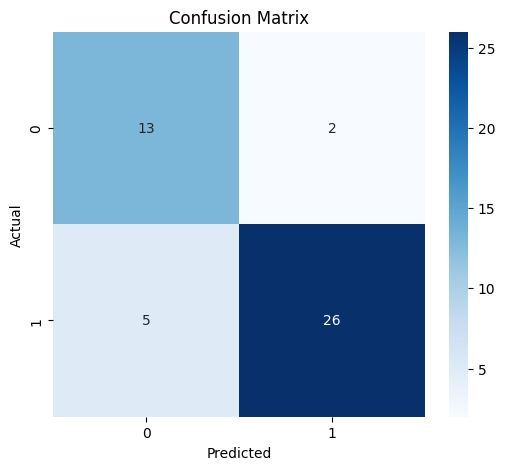

In [23]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

Precision, Recall, F1-Score

In [24]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.72      0.87      0.79        15
           1       0.93      0.84      0.88        31

    accuracy                           0.85        46
   macro avg       0.83      0.85      0.83        46
weighted avg       0.86      0.85      0.85        46



Overfitting vs Underfitting

Training Accuracy

In [25]:
train_accuracy = logistic_model.score(X_train, y_train)

print("Training Accuracy:", train_accuracy)

Training Accuracy: 0.8626373626373627


Testing Accuracy


In [26]:
test_accuracy = logistic_model.score(X_test, y_test)

print("Testing Accuracy:", test_accuracy)

Testing Accuracy: 0.8478260869565217


Comparison

In [27]:
print("Difference:", train_accuracy - test_accuracy)

Difference: 0.014811275680840952


Interpretation:

In [29]:
if train_accuracy - test_accuracy > 0.10:
    print("Model may be Overfitting")
elif train_accuracy < 0.70:
    print("Model may be Underfitting")
else:
    print("Model is Well-Fitted")

Model is Well-Fitted


Feature Importance

In [30]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

importance.sort_values(
    by="Coefficient",
    ascending=False,
    inplace=True)

print(importance)

     Feature  Coefficient
10     slope     0.777714
2         cp     0.721190
7    thalach     0.324504
6    restecg     0.084574
0        age     0.006335
5        fbs     0.000000
9    oldpeak    -0.151814
4       chol    -0.234300
8      exang    -0.248508
3   trestbps    -0.387642
12      thal    -0.797257
1        sex    -0.987390
11        ca    -1.034968


Final Conclusion

In [31]:
print("========== FINAL REPORT ==========")

print("Dataset Shape:", df.shape)

print("Training Accuracy:", train_accuracy)

print("Testing Accuracy:", test_accuracy)

print("Overall Accuracy:", accuracy)

print("\nClassification Report")

print(classification_report(y_test, y_pred))

========== FINAL REPORT ==========
Dataset Shape: (302, 14)
Training Accuracy: 0.8626373626373627
Testing Accuracy: 0.8478260869565217
Overall Accuracy: 0.8478260869565217

Classification Report
              precision    recall  f1-score   support

           0       0.72      0.87      0.79        15
           1       0.93      0.84      0.88        31

    accuracy                           0.85        46
   macro avg       0.83      0.85      0.83        46
weighted avg       0.86      0.85      0.85        46

